# CSE422 Lab Project Report (Template-Aligned)

**Project Title:** Customer Category Classification (Segmentation)

**Student Name:** <Write your name>

**Student ID:** <Write your ID>

**Section:** <Write your section>

**Course Instructor:** <Write instructor name>

**Submission Date:** <Write date>

> Note: This is a Jupyter Notebook report. “Page numbers” are not applicable here; instead, the report is organised by numbered sections and subsections.

## Table of Contents

1. Introduction
2. Dataset description (with imbalance check + EDA)
3. Dataset pre-processing (missing values, encoding, scaling)
4. Dataset splitting (train/test)
5. Model training & testing (supervised + KMeans clustering showcase)
6. Model selection / comparison analysis (accuracy, precision/recall, confusion matrix, ROC/AUC)
7. Conclusion

## 1. Introduction

This project builds a **customer segmentation classifier** using the provided dataset [Customer_Category_Classifier_Dataset.csv](Customer_Category_Classifier_Dataset.csv). Each customer belongs to one of **four segments** (A, B, C, D) stored in the target column **`Segmentation`**.

**Aim:** learn a model that can predict the correct segment for a new customer based on demographic and behavioural features.

**Why this matters (motivation):** businesses use segmentation to personalise offers, target marketing campaigns, and understand different customer groups more effectively.

**Type of problem:** this is a **multi-class classification** problem (output is a category, not a continuous number).

## 2. Dataset Description

This dataset contains customer attributes (inputs) and a target label **`Segmentation`** (output) with four classes: **A, B, C, D**.

**Template questions (answered with this dataset):**
- **How many data points?** **8068 rows**.
- **How many features?** The dataset has **10 input columns** + **1 target** (`Segmentation`) = **11 columns** total.
  - Note: `ID` is an identifier, so we **exclude it from model training** (models use 9 informative features).
- **Classification or regression?** **Classification**, because `Segmentation` is a category (A/B/C/D).
- **What kinds of features?**
  - Numeric (used): `Age`, `Work_Experience`, `Family_Size`
  - Categorical (used): `Gender`, `Ever_Married`, `Graduated`, `Profession`, `Spending_Score`, `Var_1`
  - Identifier (dropped): `ID`
- **Do we need encoding?** Yes. Models require numeric inputs, so categorical features are converted using **one-hot encoding**.
- **Is the dataset imbalanced?** Slightly (class **D** has the highest count), so we use **macro-F1** and **stratified splitting/CV**.
- **Correlation heatmap:** correlation is meaningful mainly for numeric features; we plot a heatmap for numeric columns (and optionally an encoded target for visual inspection).

The next code cells show the dataset shape, feature types, missing values, class distribution, and EDA relationships.

## Setup: Import Required Libraries

We use:
- **pandas / numpy** for data handling
- **matplotlib / seaborn** for plots
- **scikit-learn** for preprocessing, model training, and evaluation

In [21]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

DATA_PATH = Path("Customer_Category_Classifier_Dataset.csv")
df = pd.read_csv(DATA_PATH)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


### 2.1 Load and Explore the Dataset

This exploration prints:
- dataset **shape** (rows, columns)
- **feature names** and **data types**
- **missing values** per column
- **class distribution** for the target (`Segmentation`) to check imbalance
- basic numeric summary + a correlation heatmap for numeric features

Dataset shape: (8068, 11)

Columns:
['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession', 'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1', 'Segmentation']

Data types:
ID                   int64
Gender                 str
Ever_Married           str
Age                  int64
Graduated              str
Profession             str
Work_Experience    float64
Spending_Score         str
Family_Size        float64
Var_1                  str
Segmentation           str
dtype: object

Missing values:
Work_Experience    829
Family_Size        335
Ever_Married       140
Profession         124
Graduated           78
Var_1               76
ID                   0
Gender               0
Age                  0
Spending_Score       0
Segmentation         0
dtype: int64

Segmentation class distribution:
Segmentation
D    2268
A    1972
C    1970
B    1858
Name: count, dtype: int64

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Age,8068.0,43.466906,16.711696,18.0,30.0,40.0,53.0,89.0
Work_Experience,7239.0,2.641663,3.406763,0.0,0.0,1.0,4.0,14.0
Family_Size,7733.0,2.850123,1.531413,1.0,2.0,3.0,4.0,9.0


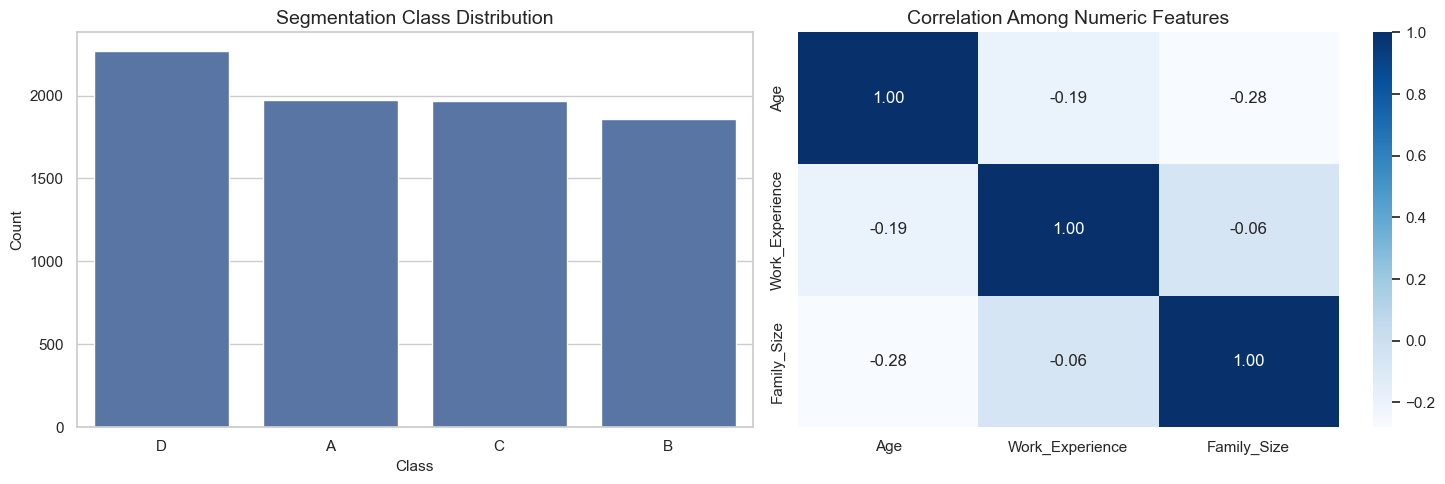

In [22]:
print(f"Dataset shape: {df.shape}")
print("\nColumns:")
print(list(df.columns))
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))
print("\nSegmentation class distribution:")
print(df["Segmentation"].value_counts())

numeric_columns = ["Age", "Work_Experience", "Family_Size"]
print("\nNumeric summary:")
display(df[numeric_columns].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="Segmentation", order=df["Segmentation"].value_counts().index, ax=axes[0])
axes[0].set_title("Segmentation Class Distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")

corr = df[numeric_columns].corr()
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f", ax=axes[1])
axes[1].set_title("Correlation Among Numeric Features")
plt.tight_layout()
plt.show()

### 2.2 Exploratory Data Analysis (EDA): Important Relationships

Goal: visually check how input features relate to the target `Segmentation` (A/B/C/D). This helps us understand which features may be informative for classification and whether there are obvious patterns or separations between classes.

Age               Work_Experience              Family_Size             
             count   mean median           count  mean median       count  mean median
Segmentation                                                                          
A             1972  44.92   41.0            1778  2.87    1.0        1877  2.44    2.0
B             1858  48.20   46.0            1666  2.38    1.0        1815  2.70    2.0
C             1970  49.14   49.0            1815  2.24    1.0        1926  2.97    3.0
D             2268  33.39   29.0            1980  3.02    1.0        2115  3.23    3.0

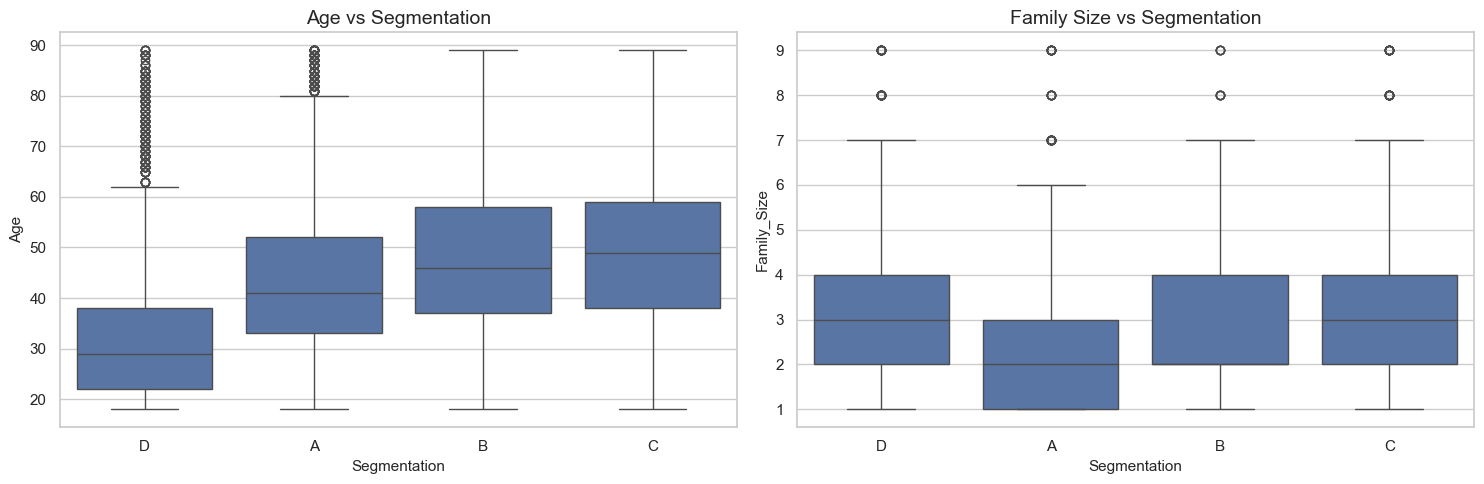


P(Gender | Segmentation) (row-normalized):


Gender,Female,Male
Segmentation,,
A,0.461,0.539
B,0.463,0.537
C,0.468,0.532
D,0.423,0.577



P(Ever_Married | Segmentation) (row-normalized):


Ever_Married,No,Yes
Segmentation,,
A,0.413,0.587
B,0.262,0.738
C,0.204,0.796
D,0.725,0.275



P(Graduated | Segmentation) (row-normalized):


Graduated,No,Yes
Segmentation,,
A,0.374,0.626
B,0.276,0.724
C,0.178,0.822
D,0.640,0.360



P(Spending_Score | Segmentation) (row-normalized):


Spending_Score,Average,High,Low
Segmentation,,,
A,0.174,0.137,0.689
B,0.318,0.207,0.476
C,0.458,0.206,0.336
D,0.061,0.069,0.870


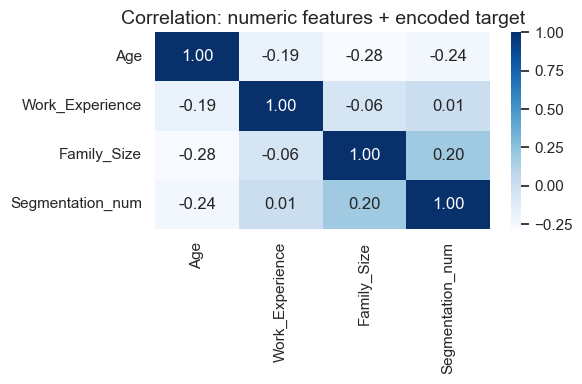

In [23]:
# Numeric feature summary by class
numeric_cols = ["Age", "Work_Experience", "Family_Size"]
display(df.groupby("Segmentation")[numeric_cols].agg(["count", "mean", "median"]).round(2))

# Boxplots: numeric features vs Segmentation
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="Segmentation", y="Age", ax=axes[0])
axes[0].set_title("Age vs Segmentation")

sns.boxplot(data=df, x="Segmentation", y="Family_Size", ax=axes[1])
axes[1].set_title("Family Size vs Segmentation")

plt.tight_layout()
plt.show()

# Categorical relationships (percentage per segment)
cat_cols = ["Gender", "Ever_Married", "Graduated", "Spending_Score"]
for col in cat_cols:
    print(f"\nP({col} | Segmentation) (row-normalized):")
    ct = pd.crosstab(df["Segmentation"], df[col], normalize="index")
    display(ct.round(3))

# Correlation heatmap with encoded target (for visual analysis only)
seg_order = sorted(df["Segmentation"].dropna().unique())
seg_map = {seg: i for i, seg in enumerate(seg_order)}
df_corr = df[numeric_cols + ["Segmentation"]].copy()
df_corr["Segmentation_num"] = df_corr["Segmentation"].map(seg_map)

plt.figure(figsize=(6, 4))
sns.heatmap(df_corr[numeric_cols + ["Segmentation_num"]].corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation: numeric features + encoded target")
plt.tight_layout()
plt.show()

### 2.3 Key EDA Observations (based on outputs above)

From the tables/plots:
- **Age is highly informative**: Segment **D** is much younger on average (~33) compared to **A/B/C** (~45–49). This separation is visible in the Age boxplot.
- **Marital status differs strongly by segment**: Segment **D** has a much higher proportion of **“No”** for `Ever_Married` (~0.73), while **B/C** are mostly **“Yes”** (~0.74–0.80).
- **Graduation status also separates groups**: Segment **C** is mostly `Graduated=Yes` (~0.82), while segment **D** has a higher `Graduated=No` (~0.64).
- **Spending_Score is useful**: Segment **D** is dominated by `Low` spending (~0.87), while **C** has a much larger `Average` share (~0.46).
- **Family size varies**: Segment **A** has smaller family size on average (~2.44), while **D** is larger (~3.23).

These relationships explain why a classifier can learn patterns that predict `Segmentation` using the input features.

## 3. Dataset Pre-processing

Real-world datasets often contain:
- **Missing values** (NaN)
- **Categorical features** (strings like Male/Female)
- Numeric features with different **scales** (e.g., Age vs Family_Size)

We solve this using a scikit-learn **Pipeline** (to avoid data leakage):
- **Drop non-informative identifiers** like `ID`
- **Impute** missing numeric values with the median
- **Impute** missing categorical values with the most frequent category
- **One-hot encode** categorical columns
- **Standardize** numeric columns (useful for KNN / SVM / Neural Net)

In [24]:
df_clean = df.copy()

numeric_impute_columns = ["Work_Experience", "Family_Size"]
categorical_impute_columns = ["Ever_Married", "Profession", "Graduated", "Var_1"]

for column in numeric_impute_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

for column in categorical_impute_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].mode(dropna=True)[0])

print("Remaining missing values after preprocessing:")
print(df_clean.isna().sum().sort_values(ascending=False))
display(df_clean.head())

Remaining missing values after preprocessing:
ID                 0
Gender             0
Ever_Married       0
Age                0
Graduated          0
Profession         0
Work_Experience    0
Spending_Score     0
Family_Size        0
Var_1              0
Segmentation       0
dtype: int64


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,1.0,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,1.0,High,6.0,Cat_6,A


## 4. Dataset Splitting (Train/Test)

We split the dataset into:
- **Training set**: used to fit/learn model parameters
- **Test set**: held-out data used only for final evaluation

We use **stratified splitting** (`stratify=y`) so that each split keeps a similar class distribution (important when classes are imbalanced).

In [25]:
target_column = "Segmentation"

# Drop ID from model features (identifier, not informative for learning)
drop_columns = ["ID"]
feature_columns = [c for c in df_clean.columns if c not in ([target_column] + drop_columns)]

X = df_clean[feature_columns]
y = df_clean[target_column]

numeric_features = ["Age", "Work_Experience", "Family_Size"]
categorical_features = [
    "Gender",
    "Ever_Married",
    "Graduated",
    "Profession",
    "Spending_Score",
    "Var_1",
]

numeric_transformer = Pipeline(steps=[("scaler", StandardScaler())])
categorical_transformer = Pipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

Training set size: (6454, 9)
Testing set size: (1614, 9)

Training class distribution:
Segmentation
D    0.281
A    0.244
C    0.244
B    0.230
Name: proportion, dtype: float64


## 5. Model Training and Testing (Supervised Learning)

We train multiple **supervised classification** models and compare their performance on the test set.

Models included (template coverage):
- Logistic Regression (baseline linear model)
- KNN (distance-based)
- Decision Tree
- Random Forest (ensemble of trees)
- Gradient Boosting (boosted ensemble)
- SVM (margin-based classifier)
- Neural Network (MLP)
- **Naive Bayes (GaussianNB)** 

All models are trained using the **same preprocessing pipeline** to ensure a fair comparison.

In [26]:
def build_pipeline(model):
    # clone(preprocessor) avoids sharing the same fitted transformer across pipelines
    return Pipeline(steps=[("preprocessor", clone(preprocessor)), ("model", model)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(n_estimators=250, random_state=42, class_weight="balanced"),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(kernel="linear", probability=True, class_weight="balanced", random_state=42),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=400, random_state=42),
}

results = []
fitted_models = {}

for model_name, estimator in models.items():
    pipeline = build_pipeline(estimator)
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    fitted_models[model_name] = pipeline
    results.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, average="macro", zero_division=0),
            "Recall": recall_score(y_test, predictions, average="macro", zero_division=0),
            "F1 Score": f1_score(y_test, predictions, average="macro", zero_division=0),
        }
    )

results_df = pd.DataFrame(results).sort_values(by="F1 Score", ascending=False).reset_index(drop=True)
display(results_df)

best_by_test_name = results_df.loc[0, "Model"]
print(f"Best model on the test set (macro F1): {best_by_test_name}")

,Model,Accuracy,Precision,Recall,F1 Score
0,Gradient Boosting,0.550805,0.534663,0.539623,0.534529
1,Logistic Regression,0.518587,0.503569,0.508489,0.504132
2,Neural Network,0.496283,0.478440,0.485774,0.479475
3,Random Forest,0.490706,0.479511,0.481039,0.479240
4,KNN,0.482652,0.477063,0.474026,0.474557
5,Naive Bayes (Gaussian),0.495663,0.478705,0.482577,0.460877
6,SVM,0.480173,0.450169,0.467989,0.436654
7,Decision Tree,0.434944,0.430072,0.427732,0.428699


Best model on the test set (macro F1): Gradient Boosting


### 5.1 Stratified K-Fold Cross-Validation (Train set only)

**Why K-Fold?** A single train/test split can be “lucky” or “unlucky”. K-Fold Cross-Validation evaluates a model multiple times on different splits of the training data.

**Important:** We run cross-validation only on the **training set** (not the test set) to avoid leaking test information into model selection.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for model_name, estimator in models.items():
    pipeline = build_pipeline(estimator)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
        n_jobs=None,
        return_train_score=False,
    )

    cv_rows.append(
        {
            "Model": model_name,
            "CV Accuracy (mean)": scores["test_accuracy"].mean(),
            "CV Accuracy (std)": scores["test_accuracy"].std(),
            "CV F1 Macro (mean)": scores["test_f1_macro"].mean(),
            "CV F1 Macro (std)": scores["test_f1_macro"].std(),
        }
    )

cv_results_df = pd.DataFrame(cv_rows).sort_values(by="CV F1 Macro (mean)", ascending=False).reset_index(drop=True)
display(cv_results_df)

best_model_name = cv_results_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]
print(f"Selected best model by CV macro F1: {best_model_name}")

,Model,CV Accuracy (mean),CV Accuracy (std),CV F1 Macro (mean),CV F1 Macro (std)
0,Gradient Boosting,0.532539,0.007532,0.517557,0.008018
1,Logistic Regression,0.504959,0.014318,0.491602,0.014351
2,Random Forest,0.478462,0.007473,0.467484,0.005069
3,Neural Network,0.480014,0.009414,0.465288,0.011237
4,KNN,0.471955,0.006918,0.464194,0.007372
5,SVM,0.480942,0.015712,0.449134,0.020250
6,Naive Bayes (Gaussian),0.471491,0.012329,0.437966,0.016311
7,Decision Tree,0.435081,0.011443,0.428864,0.011466


Selected best model by CV macro F1: Gradient Boosting


## 6. Model Evaluation and Comparison

We compare models using:
- **Accuracy**
- **Macro Precision / Macro Recall / Macro F1** (treats each class equally; good for imbalance)
- **Confusion matrices** (see which classes are confused)

Later, we also plot **ROC curves and AUC** for a deeper view of performance (especially useful when comparing classifiers beyond accuracy).

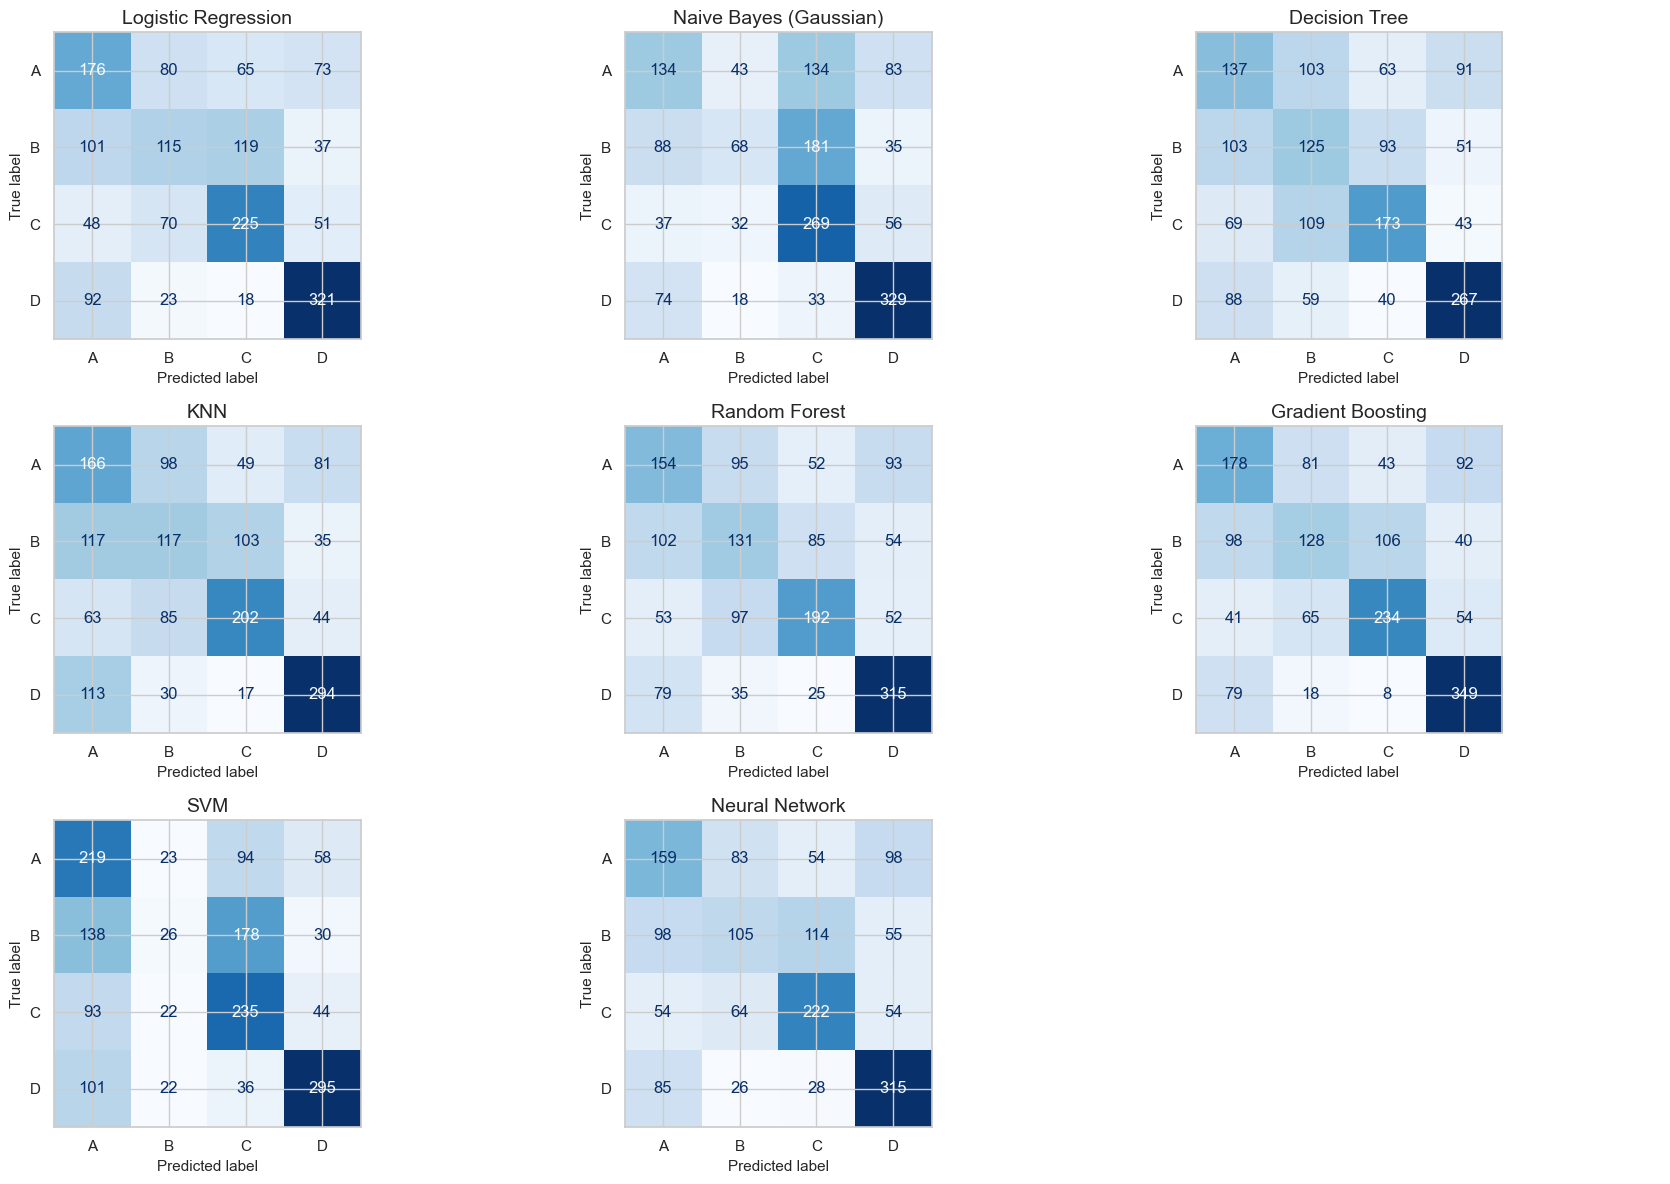

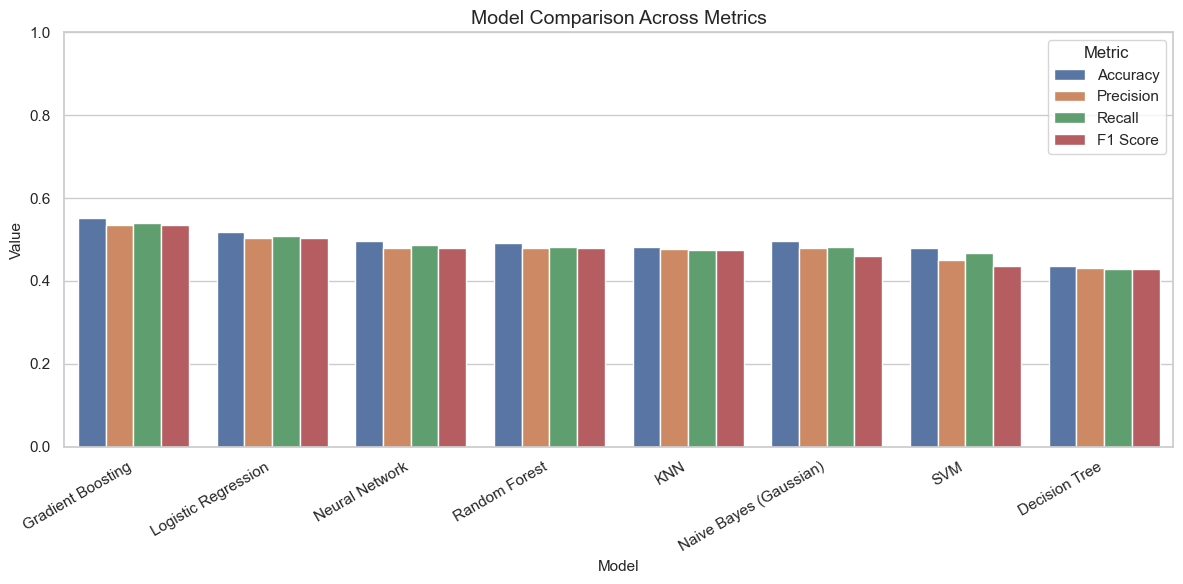

Classification report for the best model:

              precision    recall  f1-score   support

           A       0.45      0.45      0.45       394
           B       0.44      0.34      0.39       372
           C       0.60      0.59      0.60       394
           D       0.65      0.77      0.71       454

    accuracy                           0.55      1614
   macro avg       0.53      0.54      0.53      1614
weighted avg       0.54      0.55      0.54      1614



In [28]:
import math

# Confusion matrices for all trained models
n_models = len(fitted_models)
n_cols = 3
n_rows = math.ceil(n_models / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axes = np.array(axes).ravel()

labels = sorted(y.unique())

for ax, (model_name, pipeline) in zip(axes, fitted_models.items()):
    predictions = pipeline.predict(X_test)
    cm = confusion_matrix(y_test, predictions, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(model_name)

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Metric comparison bar chart
plt.figure(figsize=(12, 6))
comparison_melted = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Value",
)

sns.barplot(data=comparison_melted, x="Model", y="Value", hue="Metric")
plt.title("Model Comparison Across Metrics")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("Classification report for the best model:\n")
print(classification_report(y_test, best_model.predict(X_test), zero_division=0))

### 6.1 ROC Curve and AUC (Multi-class, One-vs-Rest)

For multi-class classification (A/B/C/D), we compute ROC/AUC using the **One-vs-Rest (OvR)** strategy:
- For each class, treat it as “positive” and all other classes as “negative”.
- Plot ROC curves and compute AUC per class.
- We also compute a **macro-average AUC** to summarise performance across classes.

,Model,Macro OvR AUC
0,Gradient Boosting,0.795106
1,Logistic Regression,0.771667
2,Neural Network,0.757837
3,Random Forest,0.750165
4,Naive Bayes (Gaussian),0.745834
5,KNN,0.733335
6,SVM,0.732490
7,Decision Tree,0.623048


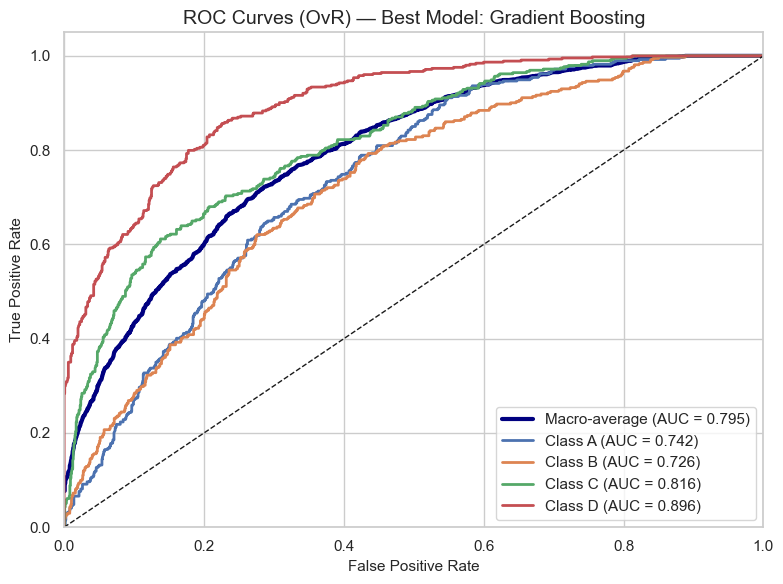

In [29]:
class_labels = sorted(y.unique())
y_test_bin = label_binarize(y_test, classes=class_labels)

auc_rows = []
proba_by_model = {}

for model_name, pipeline in fitted_models.items():
    if not hasattr(pipeline, "predict_proba"):
        auc_rows.append({"Model": model_name, "Macro OvR AUC": np.nan})
        continue

    proba = pipeline.predict_proba(X_test)

    # Align probability columns to the same class order for all models
    model_classes = list(pipeline.classes_)
    aligned_indices = [model_classes.index(cls) for cls in class_labels]
    proba_aligned = proba[:, aligned_indices]

    macro_auc = roc_auc_score(
        y_test,
        proba_aligned,
        multi_class="ovr",
        average="macro",
        labels=class_labels,
    )

    auc_rows.append({"Model": model_name, "Macro OvR AUC": macro_auc})
    proba_by_model[model_name] = proba_aligned

auc_df = pd.DataFrame(auc_rows).sort_values(by="Macro OvR AUC", ascending=False).reset_index(drop=True)
display(auc_df)

# Plot ROC curves for the best model (selected earlier by macro F1)
best_proba = proba_by_model.get(best_model_name)
if best_proba is None:
    best_proba = best_model.predict_proba(X_test)
    model_classes = list(best_model.classes_)
    aligned_indices = [model_classes.index(cls) for cls in class_labels]
    best_proba = best_proba[:, aligned_indices]

fpr = {}
tpr = {}
roc_auc = {}

for i, cls in enumerate(class_labels):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], best_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Macro-average ROC curve
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(class_labels))]))
mean_tpr = np.zeros_like(all_fpr)

for i in range(len(class_labels)):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

mean_tpr /= len(class_labels)
macro_auc = auc(all_fpr, mean_tpr)

plt.figure(figsize=(8, 6))
plt.plot(all_fpr, mean_tpr, label=f"Macro-average (AUC = {macro_auc:.3f})", linewidth=3, color="navy")

for i, cls in enumerate(class_labels):
    plt.plot(fpr[i], tpr[i], lw=2, label=f"Class {cls} (AUC = {roc_auc[i]:.3f})")

plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curves (OvR) — Best Model: {best_model_name}")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 6.2 Unsupervised Learning with KMeans (Clustering)

KMeans is an **unsupervised** algorithm (it does not use the target labels during training). We include it as an additional analysis to see whether the customers naturally form 4 clusters that resemble the known segmentation labels.

We evaluate clustering quality using the **silhouette score** and compare clusters against the true classes using a cross-tabulation.

KMeans silhouette score: 0.148

Cluster vs. known segmentation labels:


Cluster,0,1,2,3
Actual,,,,
A,0.129,0.345,0.221,0.305
B,0.100,0.242,0.167,0.491
C,0.116,0.147,0.155,0.582
D,0.478,0.200,0.197,0.126


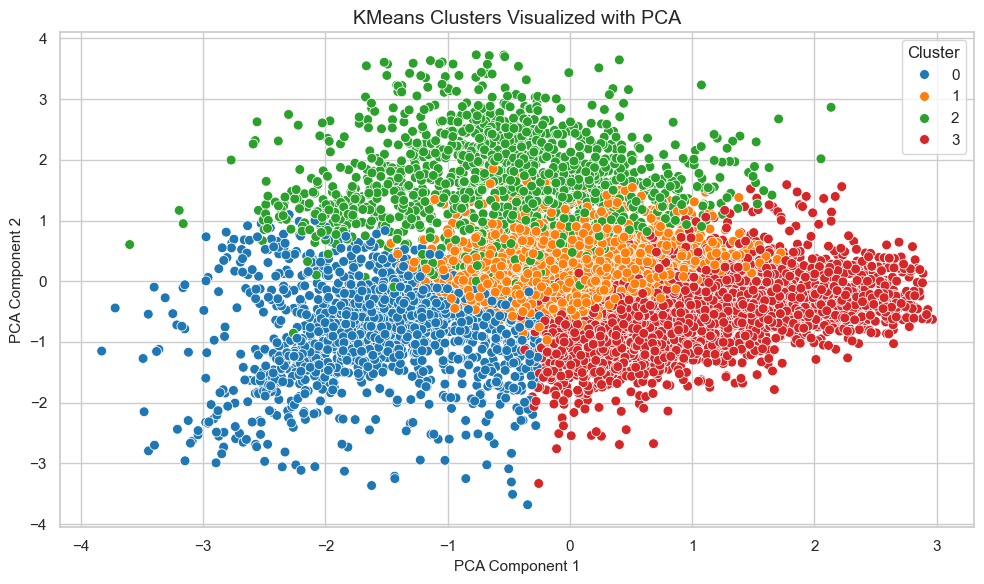

In [30]:
cluster_features = preprocessor.fit_transform(X)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(cluster_features)

print(f"KMeans silhouette score: {silhouette_score(cluster_features, cluster_labels):.3f}")
print("\nCluster vs. known segmentation labels:")
display(pd.crosstab(df_clean[target_column], cluster_labels, rownames=["Actual"], colnames=["Cluster"], normalize="index").round(3))

pca = PCA(n_components=2, random_state=42)
cluster_2d = pca.fit_transform(cluster_features)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=cluster_2d[:, 0], y=cluster_2d[:, 1], hue=cluster_labels, palette="tab10", s=50)
plt.title("KMeans Clusters Visualized with PCA")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

### 6.3 Feature Importance Analysis (Random Forest)

Tree-based models (like Random Forest) expose **feature importance** scores. This helps us interpret which inputs contribute most to the segmentation prediction.

Note: feature importance is model-specific; a different model may rank features differently.

,Feature,Importance
0,num__Age,0.364494
1,num__Work_Experience,0.149555
2,num__Family_Size,0.120375
9,cat__Profession_Artist,0.031030
14,cat__Profession_Healthcare,0.029736
20,cat__Spending_Score_Low,0.025708
26,cat__Var_1_Cat_6,0.021987
4,cat__Gender_Male,0.018231
3,cat__Gender_Female,0.018041
7,cat__Graduated_No,0.017717


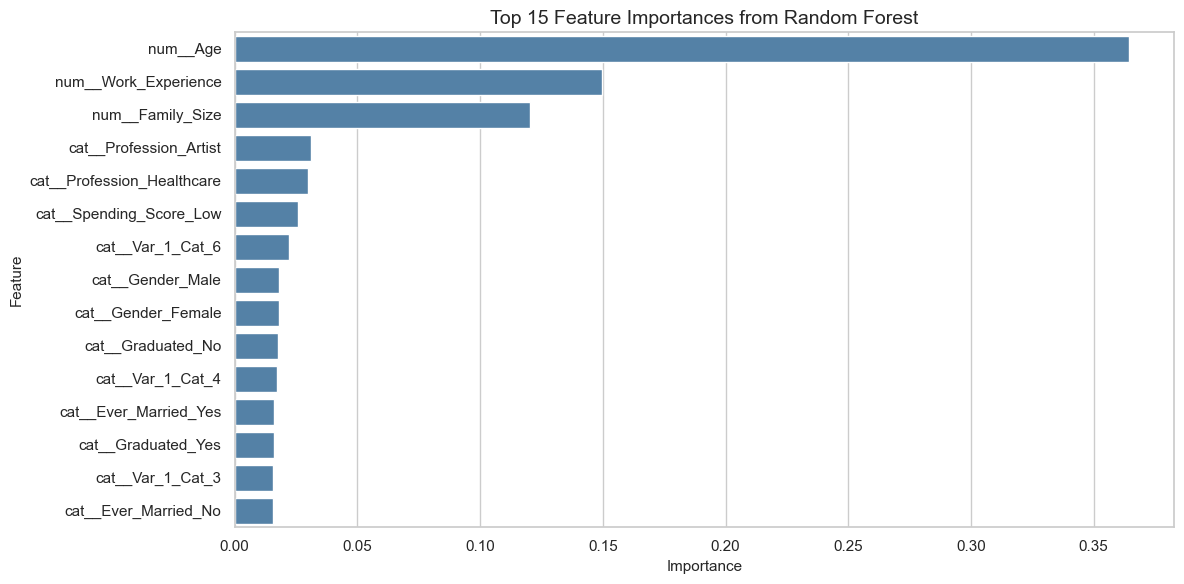

In [31]:
rf_pipeline = fitted_models["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

importance_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": rf_model.feature_importances_,
    }
).sort_values(by="Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(12, 6))
sns.barplot(data=importance_df.head(15), x="Importance", y="Feature", color="steelblue")
plt.title("Top 15 Feature Importances from Random Forest")
plt.tight_layout()
plt.show()

### 6.4 Make Predictions on New Data

After selecting the final model, we can reuse it to predict `Segmentation` for new customers (same feature columns as training). This demonstrates how the trained pipeline can be used in a real application.

In [32]:
new_customers = pd.DataFrame(
    [
        {
            "ID": 900001,
            "Gender": "Female",
            "Ever_Married": "Yes",
            "Age": 42,
            "Graduated": "Yes",
            "Profession": "Engineer",
            "Work_Experience": 5,
            "Spending_Score": "Average",
            "Family_Size": 3,
            "Var_1": "Cat_6",
        },
        {
            "ID": 900002,
            "Gender": "Male",
            "Ever_Married": "No",
            "Age": 27,
            "Graduated": "No",
            "Profession": "Healthcare",
            "Work_Experience": 1,
            "Spending_Score": "Low",
            "Family_Size": 4,
            "Var_1": "Cat_4",
        },
        {
            "ID": 900003,
            "Gender": "Female",
            "Ever_Married": "Yes",
            "Age": 68,
            "Graduated": "Yes",
            "Profession": "Lawyer",
            "Work_Experience": 0,
            "Spending_Score": "High",
            "Family_Size": 2,
            "Var_1": "Cat_6",
        },
    ]
)

new_predictions = best_model.predict(new_customers[feature_columns])
prediction_output = new_customers[["ID"]].copy()
prediction_output["Predicted_Segmentation"] = new_predictions

display(prediction_output)

print("Prediction probabilities are available for models that support predict_proba. The selected best model can be used directly for deployment or batch scoring.")

,ID,Predicted_Segmentation
0,900001,B
1,900002,D
2,900003,C


Prediction probabilities are available for models that support predict_proba. The selected best model can be used directly for deployment or batch scoring.


## 7. Conclusion

This notebook followed the full machine-learning workflow:
- Explored the dataset and checked missing values + class imbalance
- Performed EDA to understand relationships between features and `Segmentation`
- Preprocessed data (imputation, encoding, scaling)
- Trained multiple supervised models (including Naive Bayes + Neural Net)
- Selected a final model using **Stratified K-Fold Cross-Validation** on the training set
- Evaluated performance using metrics, confusion matrices, and ROC/AUC
- Demonstrated clustering (KMeans), interpretability (feature importance), and prediction on new customers

Overall, the best model depends on the metric (accuracy vs macro-F1 vs AUC), but cross-validation provides a more reliable estimate than a single split.